# Overheat warning from ECT and ambient temperature

This notebook is separate from `notebook.ipynb`.

The exploratory charts use the full telematics row, so you can see how engine coolant temperature (ECT) moves with load, speed, oil temperature, rpm, and the rest. The **model is allowed to see only ECT and ambient temperature**, plus features derived from those two series (gap, slopes, rolling means).

Each row is one second. The label is a warning window before coolant stays hot long enough to count as an overheat.

In [1]:
# Settings. Edit these, then run from the top.

DATA_CSV = None  # r"D:\Engine Overheating\telematics.csv"
LABEL_COLUMN = None

SEED = 42
N_TRIPS = 100
TEST_FRACTION = 0.20
VAL_FRACTION = 0.20

COOLANT_EVENT_C = 108.0
EXTREME_C = 115.0
SUSTAIN_S = 15
HORIZON_S = 180
MIN_RECALL = 0.70
SPIKE_C_PER_S = 5.0

# Rules built only from ECT and ambient.
RULE_ECT_C = 99.0
RULE_SLOPE_10 = 0.04
RULE_SLOPE_30 = 0.025
RULE_GAP_C = 62.0
RULE_PERSIST_S = 12
VETO_COLD_C = 80.0
VETO_FALLING_SLOPE = -0.02
VETO_FALLING_BELOW_C = 107.0

HYBRID_ECT_C = 97.0
HYBRID_SLOPE_30 = 0.02
HYBRID_STRONG_SCORE = 2
HYBRID_CONFIRM_SCORE = 3
HYBRID_CONFIRM_PERSIST = 12

DEBOUNCE_NEED = 5
DEBOUNCE_WINDOW = 8
EPISODE_GAP_S = 40

ML_TAU_GRID = [0.40, 0.55, 0.70, 0.85]
HYBRID_TAU_HIGH_GRID = [0.70, 0.85]
HYBRID_TAU_MID_GRID = [0.40, 0.60]
RULE_SCORE_GRID = [2, 3, 4]
RULE_PERSIST_GRID = [8, 12, 20]

MODEL_PARAMS = dict(
    max_iter=180,
    learning_rate=0.08,
    max_leaf_nodes=31,
    min_samples_leaf=40,
    l2_regularization=0.1,
    class_weight="balanced",
    random_state=SEED,
)

## Data

Required columns: `trip_id`, ECT (`ect_temp_c` or `coolant_temp_c`), and `ambient_temp_c`.

Load, speed, rpm, oil, throttle, intake, grade, fuel, fan, and A/C are optional. They are used in the charts when the file has them. They are not passed to the model.

Leave `DATA_CSV` empty to use the built-in 1 Hz fleet. `coolant_true_c` on that fleet is the physical temperature used only to mark events.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", context="notebook")


def _smooth_noise(rng, n, scale, win):
    kernel = np.ones(win) / win
    return np.convolve(rng.normal(0, scale, size=n), kernel, mode="same")


def _make_schedule(n, rng):
    speed = np.zeros(n)
    load = np.zeros(n)
    grade = np.zeros(n)
    i = 0
    prev_speed = float(rng.uniform(0, 40))
    while i < n:
        mode = rng.choice(["cruise", "idle", "accel", "hill", "city"])
        dur = int(rng.integers(25, 160))
        j = min(n, i + dur)
        span = j - i
        if mode == "cruise":
            target, load_span, grade_span = rng.uniform(55, 100), rng.uniform(22, 42), rng.normal(0, 0.5, size=span)
        elif mode == "idle":
            target, load_span, grade_span = 0.0, rng.uniform(8, 16), 0.0
        elif mode == "accel":
            target, load_span, grade_span = rng.uniform(40, 90), rng.uniform(65, 95), rng.normal(0, 0.8, size=span)
        elif mode == "hill":
            target, load_span, grade_span = rng.uniform(28, 60), rng.uniform(72, 96), rng.uniform(3, 8)
        else:
            target, load_span, grade_span = rng.uniform(8, 35), rng.uniform(18, 48), rng.normal(0, 1.0, size=span)
        speed[i:j] = np.linspace(prev_speed, target, span)
        load[i:j] = load_span
        grade[i:j] = grade_span
        prev_speed = float(speed[j - 1])
        i = j
    speed = np.clip(speed + _smooth_noise(rng, n, 1.2, 7), 0, 140)
    load = np.clip(load + _smooth_noise(rng, n, 2.5, 5), 0, 100)
    return speed, load, grade


def _apply_scenario(speed, load, grade, scenario, rng):
    n = len(speed)
    fan_eff = np.ones(n)
    leak = np.ones(n)
    ambient = np.full(n, float(rng.uniform(18, 32)))
    coolant0 = float(rng.uniform(86, 96))
    if scenario == "hot_stable":
        ambient[:] = rng.uniform(38, 44)
        coolant0 = rng.uniform(92, 99)
    elif scenario == "cold_start":
        coolant0 = rng.uniform(22, 45)
        ambient[:] = rng.uniform(8, 22)
    elif scenario == "overheat_traffic":
        ambient[:] = rng.uniform(36, 45)
        a = int(n * rng.uniform(0.35, 0.55))
        b = min(n, a + int(rng.integers(360, 560)))
        speed[a:b] = rng.uniform(0, 6, size=b - a)
        load[a:b] = rng.uniform(58, 82, size=b - a)
        fan_eff[a:b] = 0.08
        leak[a:b] = 0.40
    elif scenario == "overheat_fan_fail":
        ambient[:] = rng.uniform(33, 42)
        a = int(n * rng.uniform(0.25, 0.45))
        b = min(n, a + int(rng.integers(480, 780)))
        fan_eff[a:b] = 0.05
        leak[a:b] = 0.55
        speed[a:b] = rng.uniform(0, 10, size=b - a)
        load[a:b] = rng.uniform(55, 88, size=b - a)
    elif scenario == "overheat_climb":
        ambient[:] = rng.uniform(34, 43)
        a = int(n * rng.uniform(0.22, 0.40))
        b = min(n, a + int(rng.integers(420, 640)))
        speed[a:b] = rng.uniform(12, 28, size=b - a)
        load[a:b] = rng.uniform(88, 100, size=b - a)
        grade[a:b] = rng.uniform(6, 12)
        fan_eff[a:b] = 0.20
        leak[a:b] = 0.50
    elif scenario == "hill_ok":
        a = int(n * 0.4)
        b = min(n, a + int(rng.integers(90, 160)))
        speed[a:b] = rng.uniform(30, 50, size=b - a)
        load[a:b] = rng.uniform(80, 98, size=b - a)
        grade[a:b] = rng.uniform(5, 8)
    elif scenario == "heat_soak_recover":
        ambient[:] = rng.uniform(30, 40)
        a = int(n * rng.uniform(0.30, 0.55))
        b = min(n, a + int(rng.integers(70, 110)))
        speed[a:b] = rng.uniform(0, 8, size=b - a)
        load[a:b] = rng.uniform(60, 90, size=b - a)
        fan_eff[a:b] = 0.45
        leak[a:b] = 0.72
        if b < n:
            speed[b:min(n, b + 90)] = rng.uniform(45, 80)
            load[b:min(n, b + 90)] = rng.uniform(25, 40)
    return speed, load, grade, ambient, fan_eff, leak, coolant0


def _integrate(speed, load, ambient, ac, fan_eff, leak, coolant0):
    n = len(speed)
    coolant = np.empty(n)
    oil = np.empty(n)
    fan = np.zeros(n)
    rpm = 650 + load * 16.0 + speed * 18.0
    coolant[0] = coolant0
    oil[0] = coolant0 - 6 if coolant0 >= 70 else min(coolant0, ambient[0] + 8)
    for i in range(1, n):
        fan[i] = 1.0 if coolant[i - 1] >= 97 or (fan[i - 1] == 1 and coolant[i - 1] >= 91) else 0.0
        airflow = (0.10 + 0.95 * (1 - np.exp(-speed[i] / 22.0)) + 0.75 * fan[i] * fan_eff[i]) * leak[i]
        rpm_factor = 0.40 + min(rpm[i], 4800) / 4800
        heat = 0.010 + 0.085 * (load[i] / 100.0) * rpm_factor + 0.012 * ac[i]
        opening = float(np.clip((coolant[i - 1] - 84.0) / 8.0, 0.03, 1.0))
        cooling = 0.00115 * airflow * opening * max(coolant[i - 1] - ambient[i], 0.0)
        coolant[i] = coolant[i - 1] + float(np.clip(heat - cooling, -0.25, 0.20))
        oil[i] = oil[i - 1] + 0.05 * ((coolant[i] + 6 + 0.12 * load[i]) - oil[i - 1])
    return coolant, oil, fan, rpm


def simulate_fleet(n_trips=N_TRIPS, seed=SEED):
    weights = {
        "normal": 0.28, "hot_stable": 0.12, "cold_start": 0.10, "spike_noise": 0.10,
        "sensor_bias": 0.08, "hill_ok": 0.08, "heat_soak_recover": 0.10,
        "overheat_traffic": 0.08, "overheat_fan_fail": 0.08, "overheat_climb": 0.06,
    }
    rng = np.random.default_rng(seed)
    names = list(weights)
    probs = np.array(list(weights.values()), dtype=float)
    probs /= probs.sum()
    frames = []
    base = pd.Timestamp("2026-01-05 06:00:00")
    for trip_id in range(n_trips):
        scenario = str(rng.choice(names, p=probs))
        n = int(rng.integers(14 * 60, 24 * 60))
        speed, load, grade = _make_schedule(n, rng)
        speed, load, grade, ambient, fan_eff, leak, coolant0 = _apply_scenario(speed, load, grade, scenario, rng)
        ac = np.zeros(n)
        cursor = 0
        ac_rate = 0.55 if scenario.startswith("overheat") or scenario == "hot_stable" else 0.25
        while cursor < n:
            span = int(rng.integers(60, 240))
            ac[cursor:min(n, cursor + span)] = 1.0 if rng.random() < ac_rate else 0.0
            cursor += span
        coolant, oil, fan, rpm = _integrate(speed, load, ambient, ac, fan_eff, leak, coolant0)
        measured = coolant + rng.normal(0, 0.15, size=n)
        if scenario == "spike_noise":
            for _ in range(int(rng.integers(4, 9))):
                s0 = int(rng.integers(40, n - 4))
                measured[s0:s0 + int(rng.integers(1, 3))] += rng.uniform(12, 30)
        elif scenario == "sensor_bias":
            a = int(rng.integers(int(n * 0.2), int(n * 0.6)))
            rise = int(rng.integers(20, 40))
            hold = int(rng.integers(70, 140))
            bias = float(rng.uniform(10, 16))
            measured[a:a + rise] += np.linspace(0, bias, rise)[:max(0, min(rise, n - a))]
            measured[a + rise:min(n, a + rise + hold)] += bias
        ts = base + pd.Timedelta(minutes=45 * trip_id) + pd.to_timedelta(np.arange(n), unit="s")
        frames.append(pd.DataFrame({
            "timestamp": ts,
            "vehicle_id": f"V{trip_id % 40:03d}",
            "trip_id": f"T{trip_id:04d}",
            "ect_temp_c": measured,
            "coolant_true_c": coolant,
            "ambient_temp_c": ambient,
            "oil_temp_c": oil + rng.normal(0, 0.15, size=n),
            "engine_rpm": rpm,
            "engine_load_pct": load,
            "vehicle_speed_kmh": speed,
            "throttle_pct": np.clip(load + rng.normal(0, 3, size=n), 0, 100),
            "intake_air_temp_c": ambient + 4 + 0.07 * load + rng.normal(0, 0.3, size=n),
            "radiator_fan_on": fan.astype(int),
            "ac_on": ac.astype(int),
            "grade_pct": grade,
            "fuel_rate_lph": np.clip(0.5 + (load / 100.0) * (rpm / 850.0), 0, None),
            "scenario": scenario,
        }))
    return pd.concat(frames, ignore_index=True)


def load_telematics(path):
    df = pd.read_csv(path)
    if "ect_temp_c" not in df.columns and "coolant_temp_c" in df.columns:
        df["ect_temp_c"] = df["coolant_temp_c"]
    missing = [c for c in ["trip_id", "ect_temp_c", "ambient_temp_c"] if c not in df.columns]
    if missing:
        raise ValueError("CSV is missing required columns: " + ", ".join(missing))
    if "timestamp" in df.columns:
        df["timestamp"] = pd.to_datetime(df["timestamp"])
    else:
        df["timestamp"] = df.groupby("trip_id").cumcount()
    if "scenario" not in df.columns:
        df["scenario"] = "uploaded"
    return df


raw = load_telematics(DATA_CSV) if DATA_CSV else simulate_fleet()
print(f"{len(raw):,} seconds | {raw['trip_id'].nunique()} trips")
display(raw.groupby("scenario").size().rename("seconds").to_frame())
raw.head(3)

112,725 seconds | 100 trips


,seconds
scenario,
cold_start,7707
heat_soak_recover,22683
hill_ok,5652
hot_stable,12410
normal,19222
overheat_climb,9046
overheat_fan_fail,13372
overheat_traffic,5434
sensor_bias,7310


,timestamp,vehicle_id,trip_id,ect_temp_c,coolant_true_c,ambient_temp_c,oil_temp_c,engine_rpm,engine_load_pct,vehicle_speed_kmh,throttle_pct,intake_air_temp_c,radiator_fan_on,ac_on,grade_pct,fuel_rate_lph,scenario
0,2026-01-05 06:00:00,V000,T0000,89.378565,89.386956,32.280794,83.422967,2776.741953,93.978171,34.616179,88.307054,43.642597,0,0,0.102272,3.570037,heat_soak_recover
1,2026-01-05 06:00:01,V000,T0000,89.098183,89.437065,32.280794,84.507667,2773.865875,93.685145,34.716864,95.208130,42.666451,0,0,-0.252994,3.557294,heat_soak_recover
2,2026-01-05 06:00:02,V000,T0000,89.519196,89.486870,32.280794,85.774509,2777.056419,93.767305,34.821085,96.663331,43.293169,0,0,-0.013441,3.563495,heat_soak_recover


## How ECT sits with the other signals

The correlation heatmap uses every numeric telematics column on the file. A second heatmap shows mean ECT across speed bins and load bins, which is the operating region where coolant actually climbs. Scatter plots are a random sample of seconds so the clouds stay readable.

These charts are diagnostic. The training cell further down does not feed load, speed, rpm, or oil into the model.

Seconds used in the correlation table: 112,725


,mean,std,min,50%,max
ect_temp_c,92.53,12.50,22.15,91.73,134.97
ambient_temp_c,31.30,8.87,11.37,33.12,44.08
oil_temp_c,104.24,14.00,19.34,103.61,149.14
engine_rpm,2155.99,670.57,737.20,2182.91,3955.46
engine_load_pct,52.51,29.23,4.15,44.17,100.00
vehicle_speed_kmh,36.99,25.12,0.00,35.92,100.81
throttle_pct,52.51,29.36,0.00,45.10,100.00
intake_air_temp_c,38.98,9.33,15.45,40.62,55.44
grade_pct,1.49,2.87,-4.29,0.09,11.56
fuel_rate_lph,2.00,1.08,0.55,1.66,4.94


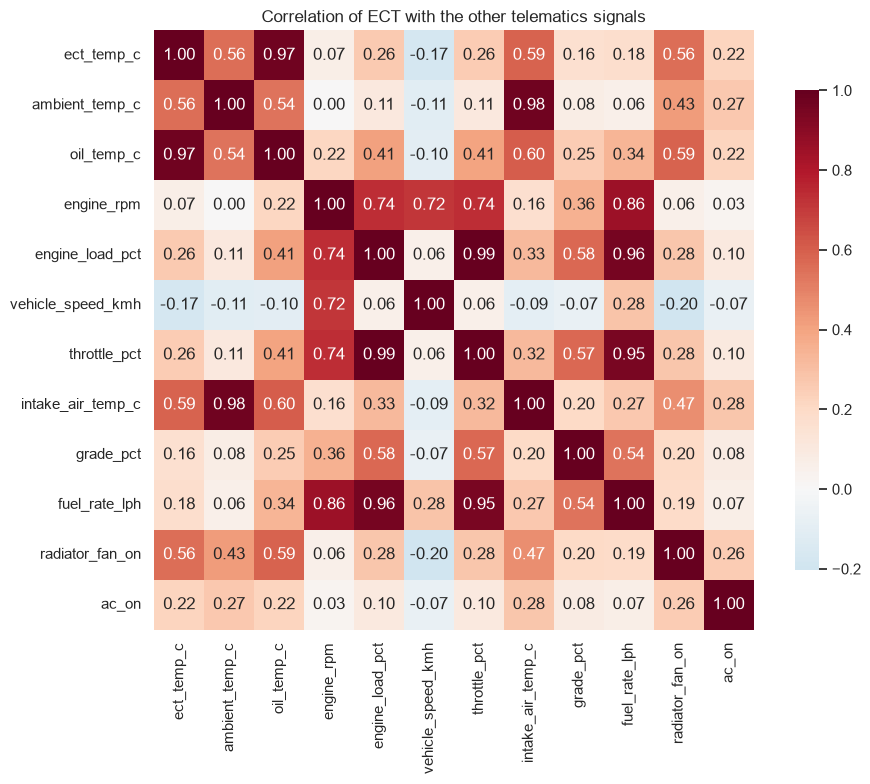

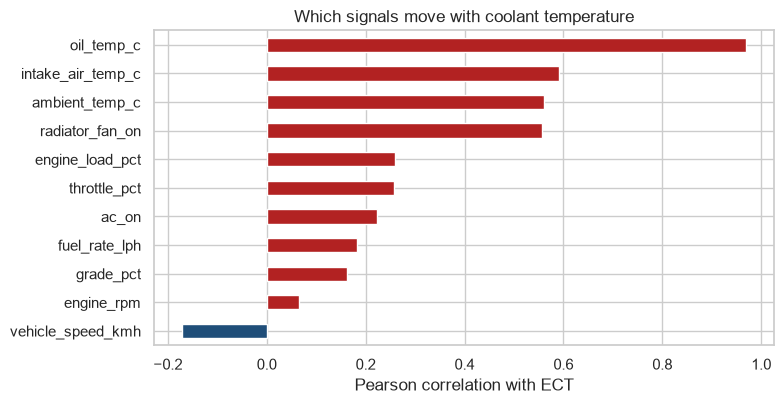

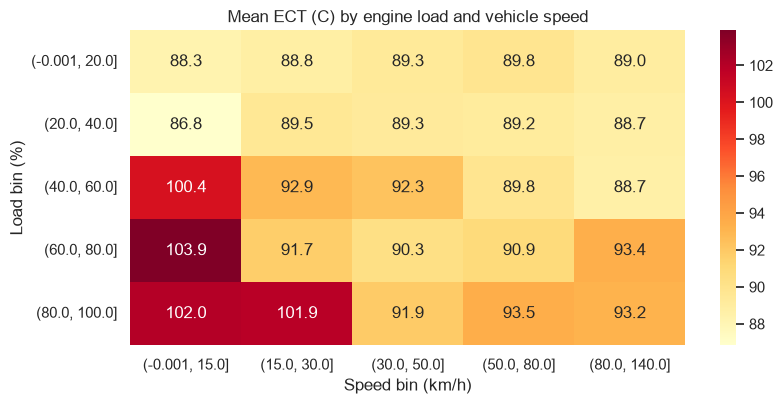

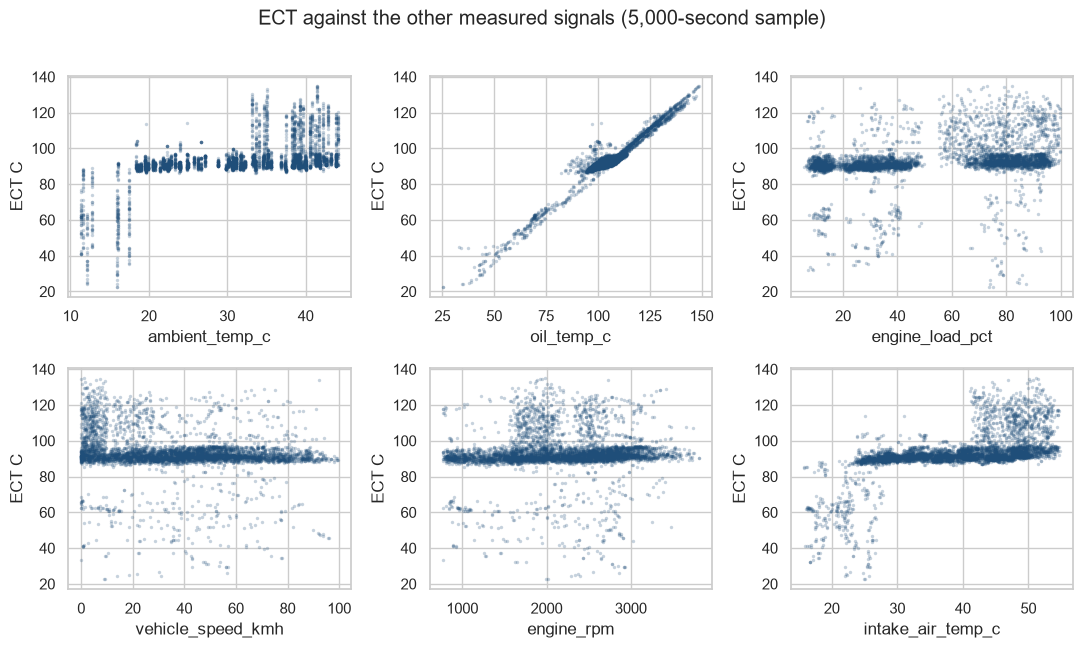

In [3]:
EDA_CANDIDATES = [
    "ect_temp_c", "ambient_temp_c", "oil_temp_c", "engine_rpm", "engine_load_pct",
    "vehicle_speed_kmh", "throttle_pct", "intake_air_temp_c", "grade_pct",
    "fuel_rate_lph", "radiator_fan_on", "ac_on",
]
eda_cols = [c for c in EDA_CANDIDATES if c in raw.columns]
eda = raw[eda_cols].apply(pd.to_numeric, errors="coerce")

print("Seconds used in the correlation table:", f"{len(eda):,}")
display(eda.describe().T[["mean", "std", "min", "50%", "max"]].round(2))

corr = eda.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, square=True, cbar_kws={"shrink": 0.8})
ax.set_title("Correlation of ECT with the other telematics signals")
fig.tight_layout()
plt.show()

ect_corr = corr["ect_temp_c"].drop("ect_temp_c").sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2))
colors = ["#b22222" if v > 0 else "#1f4e79" for v in ect_corr]
ect_corr.plot.barh(ax=ax, color=colors)
ax.set_xlabel("Pearson correlation with ECT")
ax.set_title("Which signals move with coolant temperature")
fig.tight_layout()
plt.show()

if {"engine_load_pct", "vehicle_speed_kmh"}.issubset(raw.columns):
    heat = raw[["ect_temp_c", "engine_load_pct", "vehicle_speed_kmh"]].dropna().copy()
    heat["load_bin"] = pd.cut(heat["engine_load_pct"], bins=[0, 20, 40, 60, 80, 100], include_lowest=True)
    heat["speed_bin"] = pd.cut(heat["vehicle_speed_kmh"], bins=[0, 15, 30, 50, 80, 140], include_lowest=True)
    pivot = heat.pivot_table(index="load_bin", columns="speed_bin", values="ect_temp_c", aggfunc="mean", observed=False)
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax)
    ax.set_title("Mean ECT (C) by engine load and vehicle speed")
    ax.set_xlabel("Speed bin (km/h)")
    ax.set_ylabel("Load bin (%)")
    fig.tight_layout()
    plt.show()

rng = np.random.default_rng(SEED)
sample_n = min(5000, len(raw))
sample = raw.iloc[rng.choice(len(raw), size=sample_n, replace=False)].copy()
pair_cols = [c for c in ["ambient_temp_c", "oil_temp_c", "engine_load_pct", "vehicle_speed_kmh", "engine_rpm", "intake_air_temp_c"] if c in sample.columns]
n_plots = len(pair_cols)
fig, axes = plt.subplots(int(np.ceil(n_plots / 3)), 3, figsize=(11, 3.2 * int(np.ceil(n_plots / 3))), squeeze=False)
for ax, col in zip(axes.ravel(), pair_cols):
    ax.scatter(sample[col], sample["ect_temp_c"], s=6, alpha=0.25, c="#1f4e79", linewidths=0)
    ax.set_xlabel(col)
    ax.set_ylabel("ECT C")
for ax in axes.ravel()[n_plots:]:
    ax.axis("off")
fig.suptitle("ECT against the other measured signals (5,000-second sample)", y=1.01)
fig.tight_layout()
plt.show()

## Label and ECT-only features

An event is repaired ECT at or above 108°C for 15 seconds, or a touch of 115°C. On the built-in fleet the repair is applied to the physical coolant temperature, so a sensor spike is not an event.

`y_warn` is 1 during the 180 seconds before onset. Seconds inside the event are left blank and are not used for training.

Model inputs, and only these:

- ECT level, 30s and 60s means, 10/30/60s slopes
- ambient level and 60s mean
- ECT minus ambient
- seconds ECT has been both hot and rising
- seconds ECT has been at or above 100°C in the last minute

Events: 24
Warning seconds: 4,320


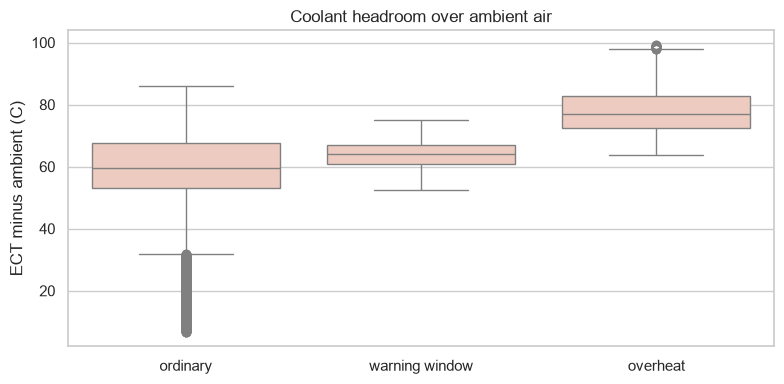

In [4]:
MODEL_FEATURES = [
    "ect_temp_c", "ect_clean", "ambient_temp_c", "ect_minus_ambient",
    "ect_slope_10s", "ect_slope_30s", "ect_slope_60s",
    "ect_mean_30s", "ect_mean_60s", "ambient_mean_60s",
    "rising_persist_s", "sec_above_100_last_60s",
]


def causal_despike(values, limit):
    y = np.asarray(values, dtype=float).copy()
    for i in range(1, len(y)):
        if abs(y[i] - y[i - 1]) > limit:
            y[i] = y[i - 1]
    return y


def consecutive_true(flag):
    flag = np.asarray(flag, dtype=int)
    out = np.zeros(len(flag), dtype=int)
    for i, bit in enumerate(flag):
        out[i] = (out[i - 1] + 1) if bit and i else int(bit)
    return out


def hot_spans(hot, repaired=None):
    spans = []
    i = 0
    n = len(hot)
    while i < n:
        if not hot[i]:
            i += 1
            continue
        j = i + 1
        while j < n and hot[j]:
            j += 1
        long_enough = (j - i) >= SUSTAIN_S
        extreme = repaired is not None and float(np.max(repaired[i:j])) >= EXTREME_C
        if long_enough or extreme or repaired is None:
            spans.append((i, j - 1))
        i = j
    return spans


def build_ect_features(df):
    pieces = []
    event_rows = []
    for trip_id, g in df.groupby("trip_id", sort=False):
        g = g.sort_values("timestamp").copy()
        raw_ect = g["ect_temp_c"].to_numpy(dtype=float)
        clean = causal_despike(raw_ect, SPIKE_C_PER_S)
        g["ect_clean"] = clean
        step = np.diff(raw_ect, prepend=raw_ect[0])
        g["sensor_spike"] = (np.abs(step) > SPIKE_C_PER_S).astype(int)

        if LABEL_COLUMN and LABEL_COLUMN in g.columns:
            spans = hot_spans(g[LABEL_COLUMN].fillna(0).to_numpy().astype(bool), repaired=None)
        else:
            truth = g["coolant_true_c"].to_numpy(dtype=float) if "coolant_true_c" in g.columns else raw_ect
            repaired = pd.Series(truth).rolling(5, center=True, min_periods=1).median().to_numpy()
            spans = hot_spans(repaired >= COOLANT_EVENT_C, repaired)

        y = np.zeros(len(g), dtype=float)
        in_event = np.zeros(len(g), dtype=bool)
        for start, end in spans:
            in_event[start:end + 1] = True
            y[max(0, start - HORIZON_S):start] = 1.0
            event_rows.append({"trip_id": trip_id, "onset_s": int(start), "end_s": int(end), "scenario": g["scenario"].iloc[0]})
        y[in_event] = np.nan
        g["y_warn"] = y
        g["in_event"] = in_event

        s = pd.Series(clean, index=g.index)
        amb = g["ambient_temp_c"]
        g["ect_minus_ambient"] = s - amb
        g["ect_slope_10s"] = (s - s.shift(10)) / 10
        g["ect_slope_30s"] = (s - s.shift(30)) / 30
        g["ect_slope_60s"] = (s - s.shift(60)) / 60
        g["ect_mean_30s"] = s.rolling(30, min_periods=10).mean()
        g["ect_mean_60s"] = s.rolling(60, min_periods=20).mean()
        g["ambient_mean_60s"] = amb.rolling(60, min_periods=20).mean()
        rising = ((s >= 98) & (g["ect_slope_10s"] >= 0.02)).fillna(False).to_numpy()
        g["rising_persist_s"] = consecutive_true(rising)
        g["sec_above_100_last_60s"] = (s >= 100).astype(float).rolling(60, min_periods=10).sum()
        pieces.append(g)
    feat = pd.concat(pieces, ignore_index=True)
    events = pd.DataFrame(event_rows)
    return feat, events


feat, events = build_ect_features(raw)
print(f"Events: {len(events)}")
print(f"Warning seconds: {int((feat['y_warn'] == 1).sum()):,}")

# ECT minus ambient, split by whether this second is a warning, an event, or ordinary driving.
state = np.where(feat["in_event"], "overheat", np.where(feat["y_warn"] == 1, "warning window", "ordinary"))
plot_df = feat[["ect_minus_ambient"]].copy()
plot_df["state"] = state
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=plot_df, x="state", y="ect_minus_ambient", order=["ordinary", "warning window", "overheat"], ax=ax, color="#f4c7b8")
ax.set_ylabel("ECT minus ambient (C)")
ax.set_xlabel("")
ax.set_title("Coolant headroom over ambient air")
fig.tight_layout()
plt.show()

## Model using only ECT and ambient

The rule score adds a point when ECT is already hot, the 10s or 30s slope is a real climb, the gap over ambient is large while temperature is still rising, or that hot-and-rising state has already lasted 12 seconds.

A second is vetoed when ECT jumps (spike), the engine is still cold, or coolant is falling back down. The hybrid alert needs the model probability and that ECT/ambient score together. Debounce keeps a flicker from becoming an episode.

In [5]:
def add_rules(df):
    ect = df["ect_clean"]
    slope10 = df["ect_slope_10s"].fillna(0)
    slope30 = df["ect_slope_30s"].fillna(0)
    gap = df["ect_minus_ambient"]
    points = [
        ect >= RULE_ECT_C,
        slope10 >= RULE_SLOPE_10,
        slope30 >= RULE_SLOPE_30,
        (gap >= RULE_GAP_C) & (slope30 > 0.01),
        df["rising_persist_s"].fillna(0) >= RULE_PERSIST_S,
    ]
    out = df.copy()
    out["rule_score"] = np.sum([p.astype(int) for p in points], axis=0)
    out["rule_veto"] = (
        (out["sensor_spike"] == 1)
        | (ect < VETO_COLD_C)
        | ((slope30 < VETO_FALLING_SLOPE) & (ect < VETO_FALLING_BELOW_C))
    )
    return out


def split_trips(df):
    meta = df.groupby("trip_id", sort=False).agg(has_event=("in_event", "max")).reset_index()
    rng = np.random.default_rng(SEED)
    train, val, test = [], [], []
    for _, part in meta.groupby("has_event"):
        ids = part["trip_id"].to_numpy().copy()
        rng.shuffle(ids)
        n = len(ids)
        n_test = int(round(n * TEST_FRACTION))
        n_val = int(round(n * VAL_FRACTION))
        if n < 5:
            n_test = 1 if n >= 3 else 0
            n_val = 1 if n >= 4 else 0
        elif n_test + n_val >= n:
            n_test = max(1, n // 5)
            n_val = max(1, n // 5)
        test.extend(ids[:n_test])
        val.extend(ids[n_test:n_test + n_val])
        train.extend(ids[n_test + n_val:])
    return set(train), set(val), set(test)


def debounce(flag):
    rolled = pd.Series(np.asarray(flag, dtype=float)).rolling(DEBOUNCE_WINDOW, min_periods=1).sum().to_numpy()
    return rolled >= DEBOUNCE_NEED


def episodes(mask):
    idx = np.flatnonzero(np.asarray(mask, dtype=bool))
    if len(idx) == 0:
        return []
    starts = [int(idx[0])]
    ends = []
    for a, b in zip(idx[:-1], idx[1:]):
        if b - a > EPISODE_GAP_S:
            ends.append(int(a))
            starts.append(int(b))
    ends.append(int(idx[-1]))
    return list(zip(starts, ends))


def score_alerts(alert, spans, n_seconds):
    found = episodes(alert)
    detected, early, leads, fp = 0, 0, [], 0
    for start, end in spans:
        hits = [s for s, e in found if e >= start - HORIZON_S and s <= end]
        if hits:
            detected += 1
            lead = start - min(hits)
            leads.append(lead)
            early += int(lead > 0)
    for s, e in found:
        fp += int(not any(e >= start - HORIZON_S and s <= end for start, end in spans))
    hours = n_seconds / 3600.0
    return dict(events=len(spans), detected=detected, early=early, leads=leads, fp_episodes=fp, alert_episodes=len(found), hours=hours)


def pack_trips(df):
    packed = {}
    for trip_id, g in df.groupby("trip_id", sort=False):
        g = g.sort_values("timestamp")
        in_event = g["in_event"].to_numpy()
        spans, i = [], 0
        while i < len(g):
            if not in_event[i]:
                i += 1
                continue
            j = i + 1
            while j < len(g) and in_event[j]:
                j += 1
            spans.append((i, j - 1))
            i = j
        packed[trip_id] = {
            "n": len(g),
            "spans": spans,
            "scenario": g["scenario"].iloc[0],
            "proba": g["proba"].to_numpy(),
            "rule_score": g["rule_score"].to_numpy(),
            "rule_veto": g["rule_veto"].to_numpy().astype(bool),
            "persist": g["rising_persist_s"].fillna(0).to_numpy(),
            "ect": g["ect_clean"].to_numpy(),
            "slope30": g["ect_slope_30s"].fillna(0).to_numpy(),
            "timestamp": g["timestamp"].to_numpy(),
        }
    return packed


def evaluate(packed, alert_fn):
    totals = {k: 0 for k in ["events", "detected", "early", "fp_episodes", "alert_episodes"]}
    totals["hours"] = 0.0
    leads = []
    for trip in packed.values():
        stats = score_alerts(alert_fn(trip), trip["spans"], trip["n"])
        for key in totals:
            totals[key] += stats[key]
        leads.extend(stats["leads"])
    caught = totals["alert_episodes"] - totals["fp_episodes"]
    return {
        "recall": totals["detected"] / totals["events"] if totals["events"] else np.nan,
        "early_recall": totals["early"] / totals["events"] if totals["events"] else np.nan,
        "precision": caught / totals["alert_episodes"] if totals["alert_episodes"] else np.nan,
        "fp_per_hour": totals["fp_episodes"] / totals["hours"] if totals["hours"] else np.nan,
        "fp_episodes": totals["fp_episodes"],
        "detected": totals["detected"],
        "events": totals["events"],
        "median_lead_s": float(np.median(leads)) if leads else np.nan,
    }


def _with(overrides=None):
    chosen = {"ml_tau": 0.6, "tau_high": 0.8, "tau_mid": 0.5, "rule_score": 3, "rule_persist": 12}
    if "CHOSEN" in globals():
        chosen.update(CHOSEN)
    if overrides:
        chosen.update({k: v for k, v in overrides.items() if v is not None})
    return chosen


def rule_alert(trip, overrides=None):
    p = _with(overrides)
    raw = (
        (trip["rule_score"] >= p["rule_score"])
        & (trip["persist"] >= p["rule_persist"])
        & (trip["ect"] >= HYBRID_ECT_C)
        & ~trip["rule_veto"]
    )
    return debounce(raw)


def ml_alert(trip, overrides=None):
    return debounce(trip["proba"] >= _with(overrides)["ml_tau"])


def hybrid_alert(trip, overrides=None):
    p = _with(overrides)
    strong = (
        (trip["proba"] >= p["tau_high"])
        & (trip["ect"] >= HYBRID_ECT_C)
        & (trip["slope30"] >= HYBRID_SLOPE_30)
        & (trip["rule_score"] >= HYBRID_STRONG_SCORE)
    )
    confirmed = (
        (trip["proba"] >= p["tau_mid"])
        & (trip["rule_score"] >= HYBRID_CONFIRM_SCORE)
        & (trip["persist"] >= HYBRID_CONFIRM_PERSIST)
        & (trip["ect"] >= RULE_ECT_C - 3)
    )
    return debounce((strong | confirmed) & ~trip["rule_veto"])


def pick(rows):
    eligible = [r for r in rows if pd.notna(r["recall"]) and r["recall"] >= MIN_RECALL]
    pool = eligible or rows
    def sort_key(r):
        lead = r["median_lead_s"] if pd.notna(r["median_lead_s"]) else -1e9
        return (r["fp_per_hour"], -r["recall"], -lead)
    return sorted(pool, key=sort_key)[0]


feat = add_rules(feat)
train_ids, val_ids, test_ids = split_trips(feat)
feat["split"] = np.where(feat["trip_id"].isin(train_ids), "train", np.where(feat["trip_id"].isin(val_ids), "val", "test"))
train = feat[(feat["split"] == "train") & feat["y_warn"].notna()].copy()
print("Model features:", ", ".join(MODEL_FEATURES))
print(f"Train seconds {len(train):,} | warning seconds {int(train['y_warn'].sum()):,}")

model = HistGradientBoostingClassifier(**MODEL_PARAMS)
model.fit(train[MODEL_FEATURES], train["y_warn"].astype(int))
feat["proba"] = model.predict_proba(feat[MODEL_FEATURES])[:, 1]

val_ok = (feat["split"] == "val") & feat["y_warn"].notna()
print("Validation average precision:", round(average_precision_score(feat.loc[val_ok, "y_warn"].astype(int), feat.loc[val_ok, "proba"]), 3))

val_packed = pack_trips(feat[feat["split"] == "val"])
test_packed = pack_trips(feat[feat["split"] == "test"])


def search(candidates, alert_from_row):
    rows = []
    for spec in candidates:
        stats = evaluate(val_packed, lambda trip, spec=spec: alert_from_row(trip, spec))
        row = dict(spec)
        row.update(stats)
        rows.append(row)
    return rows


best_ml = pick(search([{"ml_tau": t} for t in ML_TAU_GRID], ml_alert))
best_rule = pick(search([{"rule_score": s, "rule_persist": p} for s in RULE_SCORE_GRID for p in RULE_PERSIST_GRID], rule_alert))
best_hy = pick(search([{"tau_high": hi, "tau_mid": mid} for hi in HYBRID_TAU_HIGH_GRID for mid in HYBRID_TAU_MID_GRID], hybrid_alert))
CHOSEN = {
    "ml_tau": best_ml["ml_tau"],
    "tau_high": best_hy["tau_high"],
    "tau_mid": best_hy["tau_mid"],
    "rule_score": best_rule["rule_score"],
    "rule_persist": best_rule["rule_persist"],
}
print("Operating point:", CHOSEN)

rows = []
for name, fn in [("ect_ambient_rules", rule_alert), ("ect_ambient_ml", ml_alert), ("ect_ambient_hybrid", hybrid_alert)]:
    stats = evaluate(test_packed, fn)
    rows.append({
        "model": name,
        "recall": stats["recall"],
        "early_recall": stats["early_recall"],
        "precision": stats["precision"],
        "false_alarms_per_hour": stats["fp_per_hour"],
        "false_alarms": stats["fp_episodes"],
        "events_caught": f"{stats['detected']}/{stats['events']}",
        "median_lead_s": stats["median_lead_s"],
    })
results = pd.DataFrame(rows).set_index("model")
display(results.round(3))

Model features: ect_temp_c, ect_clean, ambient_temp_c, ect_minus_ambient, ect_slope_10s, ect_slope_30s, ect_slope_60s, ect_mean_30s, ect_mean_60s, ambient_mean_60s, rising_persist_s, sec_above_100_last_60s
Train seconds 61,104 | warning seconds 2,520


Validation average precision: 0.987
Operating point: {'ml_tau': 0.4, 'tau_high': 0.7, 'tau_mid': 0.4, 'rule_score': 2, 'rule_persist': 20}


,recall,early_recall,precision,false_alarms_per_hour,false_alarms,events_caught,median_lead_s
model,,,,,,,
ect_ambient_rules,1.0,1.0,0.957,0.154,1,5/5,127.0
ect_ambient_ml,1.0,1.0,0.714,0.308,2,5/5,181.0
ect_ambient_hybrid,1.0,1.0,1.000,0.000,0,5/5,174.0


## One test trip

Shaded temperature is the overheat itself. The lower panel is the ECT-and-ambient model probability and the hybrid alert. Change `COOLANT_EVENT_C`, `HORIZON_S`, or the rule gates in the settings cell and run from the top to retune.

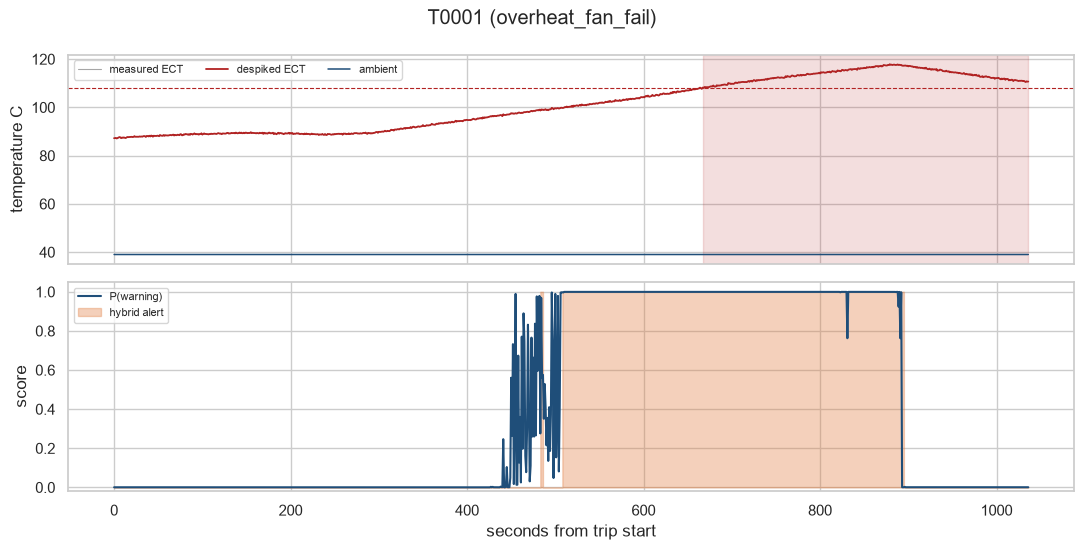

In [6]:
def plot_trip(trip_id):
    g = feat[feat["trip_id"] == trip_id].sort_values("timestamp")
    trip = pack_trips(g)[trip_id]
    t = np.arange(trip["n"])
    fig, axes = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
    axes[0].plot(t, g["ect_temp_c"].to_numpy(), color="0.65", lw=0.8, label="measured ECT")
    axes[0].plot(t, trip["ect"], color="#b22222", lw=1.3, label="despiked ECT")
    axes[0].plot(t, g["ambient_temp_c"].to_numpy(), color="#1f4e79", lw=1.1, label="ambient")
    axes[0].axhline(COOLANT_EVENT_C, color="#b22222", ls="--", lw=0.8)
    for start, end in trip["spans"]:
        axes[0].axvspan(start, end, color="#b22222", alpha=0.15)
    axes[0].set_ylabel("temperature C")
    axes[0].legend(loc="upper left", ncol=3, fontsize=8)
    alert = hybrid_alert(trip).astype(float)
    axes[1].plot(t, trip["proba"], color="#1f4e79", label="P(warning)")
    axes[1].fill_between(t, 0, alert, step="pre", color="#e07a3d", alpha=0.35, label="hybrid alert")
    axes[1].set_ylim(-0.02, 1.05)
    axes[1].set_ylabel("score")
    axes[1].set_xlabel("seconds from trip start")
    axes[1].legend(loc="upper left", fontsize=8)
    fig.suptitle(f"{trip_id} ({trip['scenario']})")
    fig.tight_layout()
    plt.show()


test_events = feat[(feat["split"] == "test") & feat["in_event"]]
if len(test_events):
    plot_trip(test_events["trip_id"].iloc[0])
else:
    print("No test trip contains an overheat. Raise N_TRIPS and run again.")